# Лабораторная работа №1 — Визуализация данных
## Датасет: Titanic (Пассажиры Титаника)

**Целевая переменная:** `survived` — выжил пассажир (1) или нет (0).

## Все признаки датасета (15 столбцов)

| Признак | Тип | Описание | Зачем нужен |
|---|---|---|---|
| `survived` | int (0/1) | **Целевая переменная**: выжил (1) или погиб (0) | То, что мы предсказываем / анализируем |
| `pclass` | int (1,2,3) | **Класс каюты**: 1й = люкс, 2й = средний, 3й = дешёвый | Социальное положение; чем выше класс, тем больше шансов выжить |
| `sex` | строка | **Пол**: male / female | Одна из важнейших переменных: женщин эвакуировали первыми |
| `age` | float | **Возраст** в годах | Детей спасали первыми; ~20% значений отсутствует |
| `sibsp` | int | **Братья/сёстры + супруги** на борту | Размер семьи; большая семья = сложнее эвакуироваться |
| `parch` | int | **Родители/дети** на борту | Аналогично: часть структуры семьи |
| `fare` | float | **Цена билета** в фунтах | Косвенно отражает класс и богатство; есть сильные выбросы |
| `embarked` | строка | **Порт посадки**: C=Шербур, Q=Квинстаун, S=Саутгемптон | Разные порты → разный состав пассажиров |
| `class` | category | **Класс каюты** словами: First/Second/Third | Дублирует `pclass` — удаляем |
| `who` | строка | man / woman / child | Дублирует `sex` + `age` — удаляем |
| `adult_male` | bool | True = взрослый мужчина | Дублирует `sex` — удаляем |
| `deck` | category | **Палуба**: A, B, C, D, E, F, G | Местоположение каюты; 77% пропусков — удаляем |
| `embark_town` | строка | Город посадки (Cherbourg, Queenstown, Southampton) | Дублирует `embarked` — удаляем |
| `alive` | строка | "yes" / "no" | Дублирует `survived` строками — удаляем |
| `alone` | bool | True = путешествовал один | Можно вычислить: `sibsp==0 & parch==0` — удаляем |


**Задачи:**
1. Очистка данных от пропусков и выбросов
2. Преобразование признаков (кодирование, масштабирование)
3. Сравнение данных до и после преобразования

4. Отображение максимального объёма данных без снижения размерности6. Визуализация структуры, распределений, зависимостей
5. Снижение размерности: PCA, t-SNE, MDS

---
## 1. Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, MDS
from pandas.plotting import parallel_coordinates

# Настройка стиля графиков
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

plt.rcParams['figure.figsize'] = (10, 5)
print('Библиотеки успешно загружены!')


Библиотеки успешно загружены!


---
## 2. Загрузка и первичный осмотр данных

In [2]:
# Загружаем встроенный датасет seaborn (не нужно скачивать вручную)
df_raw = sns.load_dataset('titanic')

print(f'Размер датасета: {df_raw.shape[0]} строк × {df_raw.shape[1]} столбцов')
df_raw.head(10)

Размер датасета: 891 строк × 15 столбцов


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [3]:
# Типы данных и непустые значения
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
# Базовая статистика числовых признаков
df_raw.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


---
## 3. Анализ пропущенных значений

In [5]:
# Считаем пропуски по каждому столбцу
missing = df_raw.isnull().sum()
missing_pct = (df_raw.isnull().mean() * 100).round(1)
missing_df = pd.DataFrame({'Пропусков': missing, '%': missing_pct})
missing_df = missing_df[missing_df['Пропусков'] > 0].sort_values('Пропусков', ascending=False)
print(missing_df.to_string())

             Пропусков     %
deck               688  77.2
age                177  19.9
embarked             2   0.2
embark_town          2   0.2


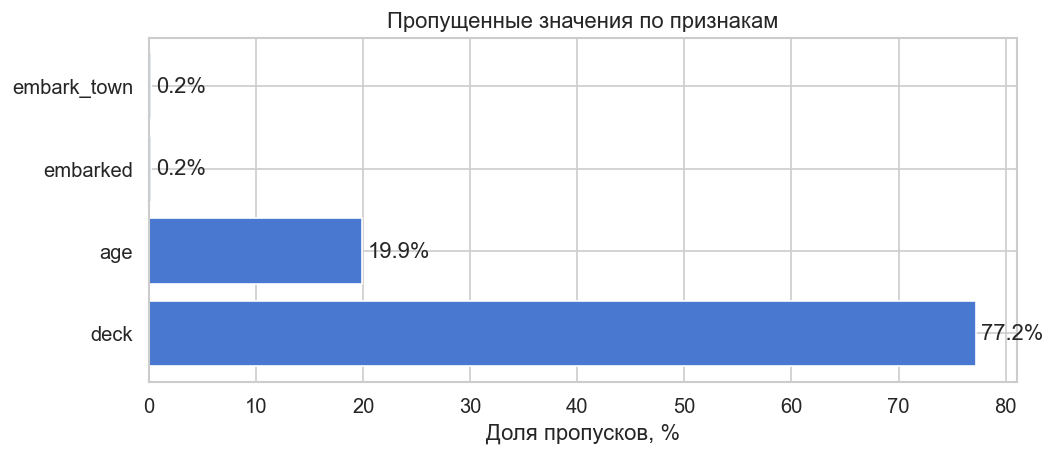

In [6]:
# Визуализация пропущенных значений
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(missing_df.index, missing_df['%'], color=sns.color_palette('muted')[0])
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xlabel('Доля пропусков, %')
ax.set_title('Пропущенные значения по признакам')
plt.tight_layout()
plt.show()

### Выводы по пропускам:
- **`deck`** — ~77% пропусков → удаляем столбец (слишком мало данных).
- **`age`** — ~20% пропусков → заполняем **медианой** (устойчива к выбросам).
- **`embarked`**, **`embark_town`** — единичные пропуски → заполняем **модой** (наиболее частое значение).

---
## 4. Очистка данных

In [7]:
# Работаем с копией, чтобы не испортить исходные данные
df = df_raw.copy()

# 4.1 Удаляем столбцы с критическим количеством пропусков или дублирующие информацию
cols_to_drop = ['deck',       # 77% пропусков
                'class',      # дублирует pclass (строковая версия)
                'who',        # дублирует sex + age
                'adult_male', # дублирует sex
                'alive',      # дублирует survived (строковая версия)
                'alone']      # можно вычислить из sibsp + parch
df = df.drop(columns=cols_to_drop)

# 4.2 Заполняем пропуски
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# 4.3 Проверка
print('Пропуски после очистки:')
print(df.isnull().sum())
print(f'\nРазмер после удаления столбцов: {df.shape}')

Пропуски после очистки:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
embark_town    0
dtype: int64

Размер после удаления столбцов: (891, 9)


### 4.2 Обнаружение и удаление выбросов (метод IQR)

Метод IQR (межквартильный размах): выброс — значение, выходящее за пределы `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`.

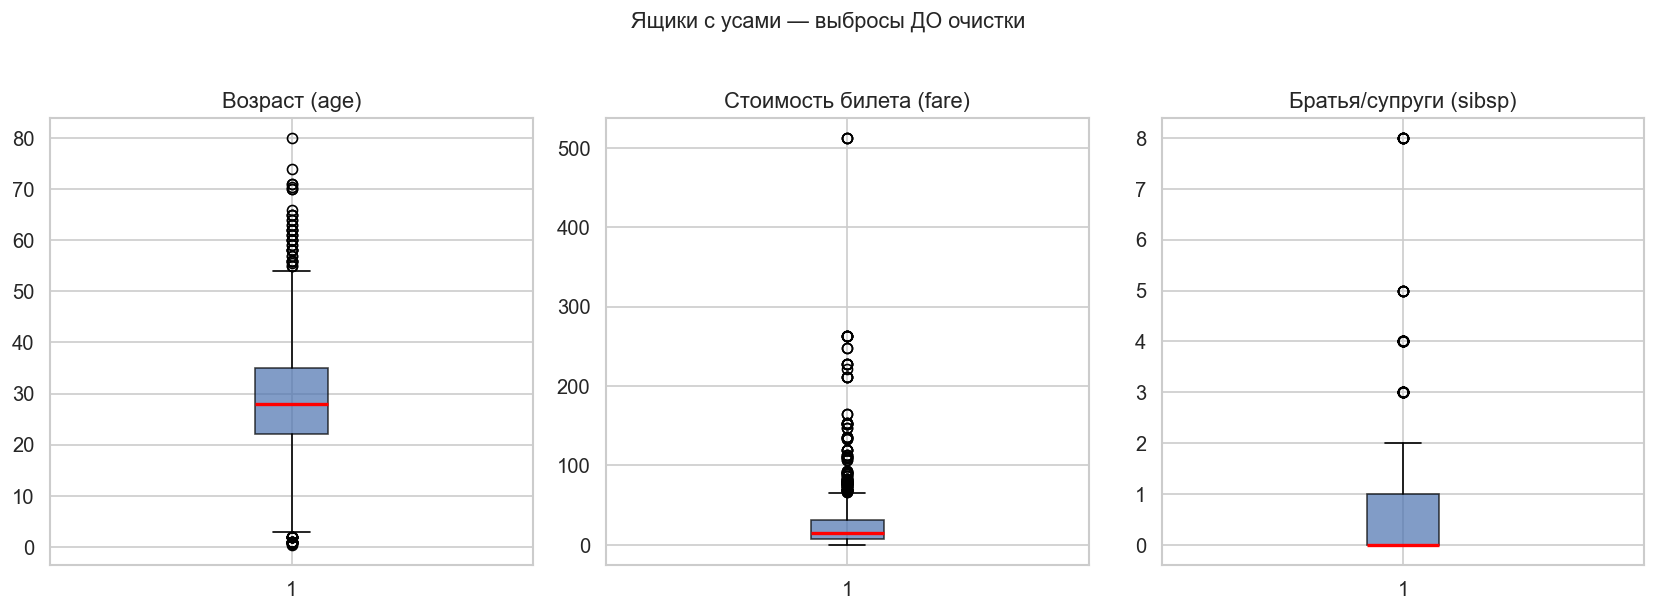

In [8]:
# Визуализируем выбросы ДО очистки
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
numeric_cols = ['age', 'fare', 'sibsp']
titles = ['Возраст (age)', 'Стоимость билета (fare)', 'Братья/супруги (sibsp)']

for ax, col, title in zip(axes, numeric_cols, titles):
    ax.boxplot(df[col], patch_artist=True,
               boxprops=dict(facecolor='#4C72B0', alpha=0.7),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(title)
    ax.set_xlabel('')

plt.suptitle('Ящики с усами — выбросы ДО очистки', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [9]:
def remove_outliers_iqr(dataframe, columns):
    """Удаляет строки с выбросами по методу IQR для указанных столбцов."""
    df_clean = dataframe.copy()
    report = []
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        n_before = len(df_clean)
        df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]
        n_removed = n_before - len(df_clean)
        report.append({'Признак': col, 'Нижняя граница': round(lower, 2),
                        'Верхняя граница': round(upper, 2), 'Удалено строк': n_removed})
    return df_clean, pd.DataFrame(report)

# Применяем только к fare — он имеет наибольший хвост
df, outlier_report = remove_outliers_iqr(df, ['fare'])

print('Отчёт об удалении выбросов:')
print(outlier_report.to_string(index=False))
print(f'\nРазмер датасета после удаления выбросов: {df.shape}')

Отчёт об удалении выбросов:
Признак  Нижняя граница  Верхняя граница  Удалено строк
   fare          -26.72            65.63            116

Размер датасета после удаления выбросов: (775, 9)


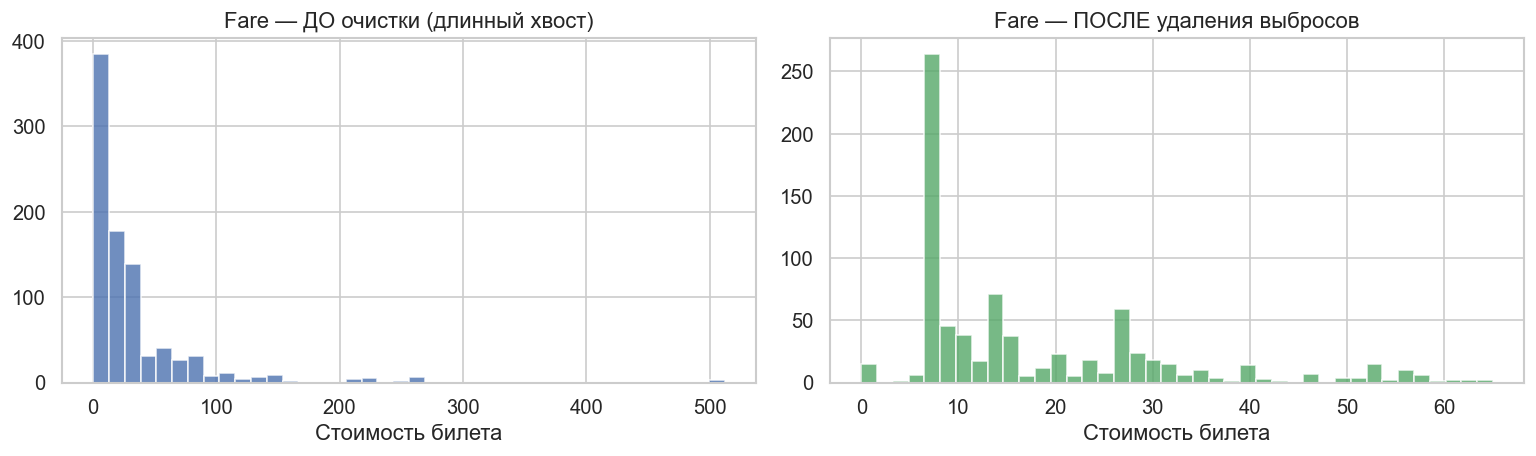

In [10]:
# Сравнение распределения fare ДО и ПОСЛЕ удаления выбросов
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df_raw['fare'].dropna(), bins=40, color='#4C72B0', alpha=0.8, edgecolor='white')
axes[0].set_title('Fare — ДО очистки (длинный хвост)')
axes[0].set_xlabel('Стоимость билета')

axes[1].hist(df['fare'], bins=40, color='#55A868', alpha=0.8, edgecolor='white')
axes[1].set_title('Fare — ПОСЛЕ удаления выбросов')
axes[1].set_xlabel('Стоимость билета')

plt.tight_layout()
plt.show()

---
## 5. Преобразование признаков

### 5.1 Кодирование категориальных переменных

In [11]:
# Уникальные значения категориальных признаков
cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
print('Категориальные признаки:')
for col in cat_cols:
    print(f'  {col}: {df[col].unique()}')

Категориальные признаки:
  sex: ['male' 'female']
  embarked: ['S' 'Q' 'C']
  embark_town: ['Southampton' 'Queenstown' 'Cherbourg']


In [12]:
df_encoded = df.copy()

# Бинарный признак: sex -> 0 (female) / 1 (male)
df_encoded['sex'] = df_encoded['sex'].map({'male': 1, 'female': 0})

# Порт посадки: One-Hot Encoding (создаём отдельную колонку для каждого порта)
embarked_dummies = pd.get_dummies(df_encoded['embarked'], prefix='embarked', dtype=int)
df_encoded = pd.concat([df_encoded.drop(columns=['embarked', 'embark_town']), embarked_dummies], axis=1)

print('Признаки после кодирования:')
print(df_encoded.dtypes)
df_encoded.head(5)

Признаки после кодирования:
survived        int64
pclass          int64
sex             int64
age           float64
sibsp           int64
parch           int64
fare          float64
embarked_C      int32
embarked_Q      int32
embarked_S      int32
dtype: object


,survived,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
0,0,3,1,22.0,1,0,7.2500,0,0,1
2,1,3,0,26.0,0,0,7.9250,0,0,1
3,1,1,0,35.0,1,0,53.1000,0,0,1
4,0,3,1,35.0,0,0,8.0500,0,0,1
5,0,3,1,28.0,0,0,8.4583,0,1,0


### 5.2 Масштабирование числовых признаков

- **Min-Max нормализация** — приводит значения к диапазону [0, 1]. Подходит, когда важны относительные значения.
- **Стандартизация (Z-score)** — среднее = 0, стандартное отклонение = 1.

In [13]:
scale_cols = ['age', 'fare', 'sibsp', 'parch']

# Min-Max нормализация
minmax = MinMaxScaler()
df_minmax = df_encoded.copy()
df_minmax[scale_cols] = minmax.fit_transform(df_encoded[scale_cols])

# Стандартизация
std_scaler = StandardScaler()
df_scaled = df_encoded.copy()
df_scaled[scale_cols] = std_scaler.fit_transform(df_encoded[scale_cols])

# Сравниваем статистики
comparison = pd.DataFrame({
    'Исходные (mean)': df_encoded[scale_cols].mean().round(2),
    'Исходные (std)':  df_encoded[scale_cols].std().round(2),
    'MinMax (mean)':   df_minmax[scale_cols].mean().round(3),
    'MinMax (max)':    df_minmax[scale_cols].max().round(3),
    'Std (mean)':      df_scaled[scale_cols].mean().round(3),
    'Std (std)':       df_scaled[scale_cols].std().round(3),
})
print(comparison)

       Исходные (mean)  Исходные (std)  MinMax (mean)  MinMax (max)  \
age              28.75           12.78          0.356           1.0   
fare             17.82           13.58          0.274           1.0   
sibsp             0.44            0.90          0.087           1.0   
parch             0.34            0.79          0.057           1.0   

       Std (mean)  Std (std)  
age          -0.0      1.001  
fare          0.0      1.001  
sibsp        -0.0      1.001  
parch         0.0      1.001  


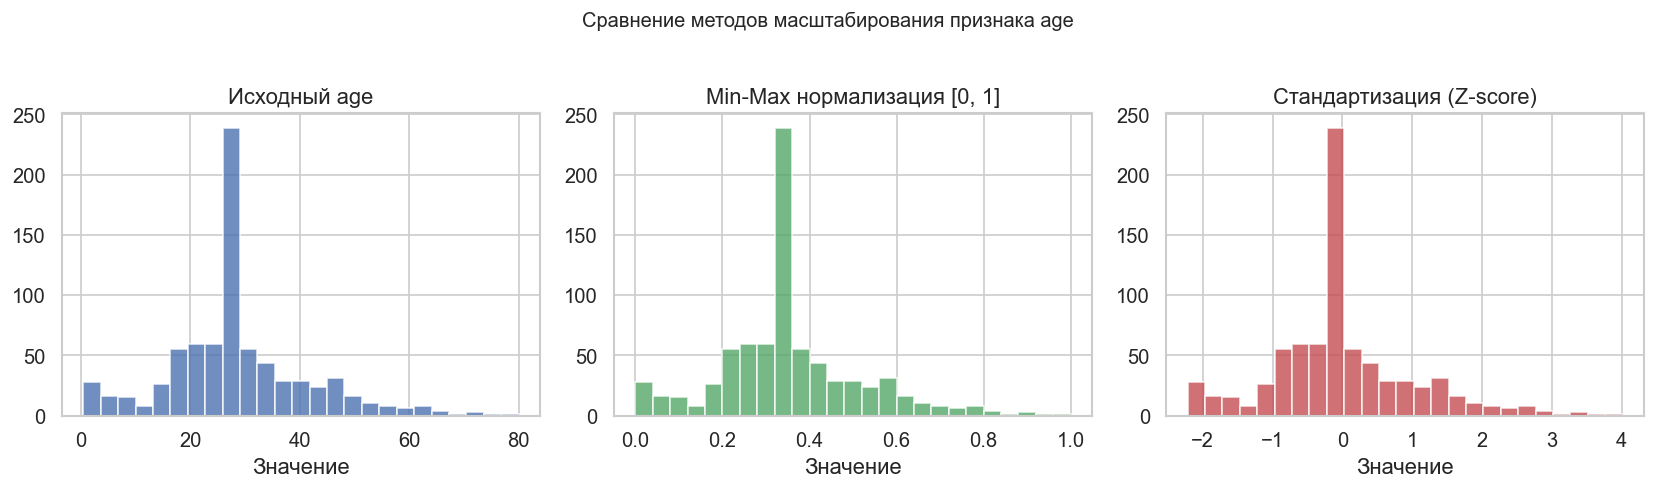

Форма распределения не меняется! Меняется только масштаб оси X.


In [14]:
# Наглядное сравнение: как масштабирование меняет распределение age
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(df_encoded['age'], bins=25, color='#4C72B0', alpha=0.8, edgecolor='white')
axes[0].set_title('Исходный age')
axes[0].set_xlabel('Значение')

axes[1].hist(df_minmax['age'], bins=25, color='#55A868', alpha=0.8, edgecolor='white')
axes[1].set_title('Min-Max нормализация [0, 1]')
axes[1].set_xlabel('Значение')

axes[2].hist(df_scaled['age'], bins=25, color='#C44E52', alpha=0.8, edgecolor='white')
axes[2].set_title('Стандартизация (Z-score)')
axes[2].set_xlabel('Значение')

plt.suptitle('Сравнение методов масштабирования признака age', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()
print('Форма распределения не меняется! Меняется только масштаб оси X.')

---
### 5.3 Сравнение данных до и после преобразования признаков


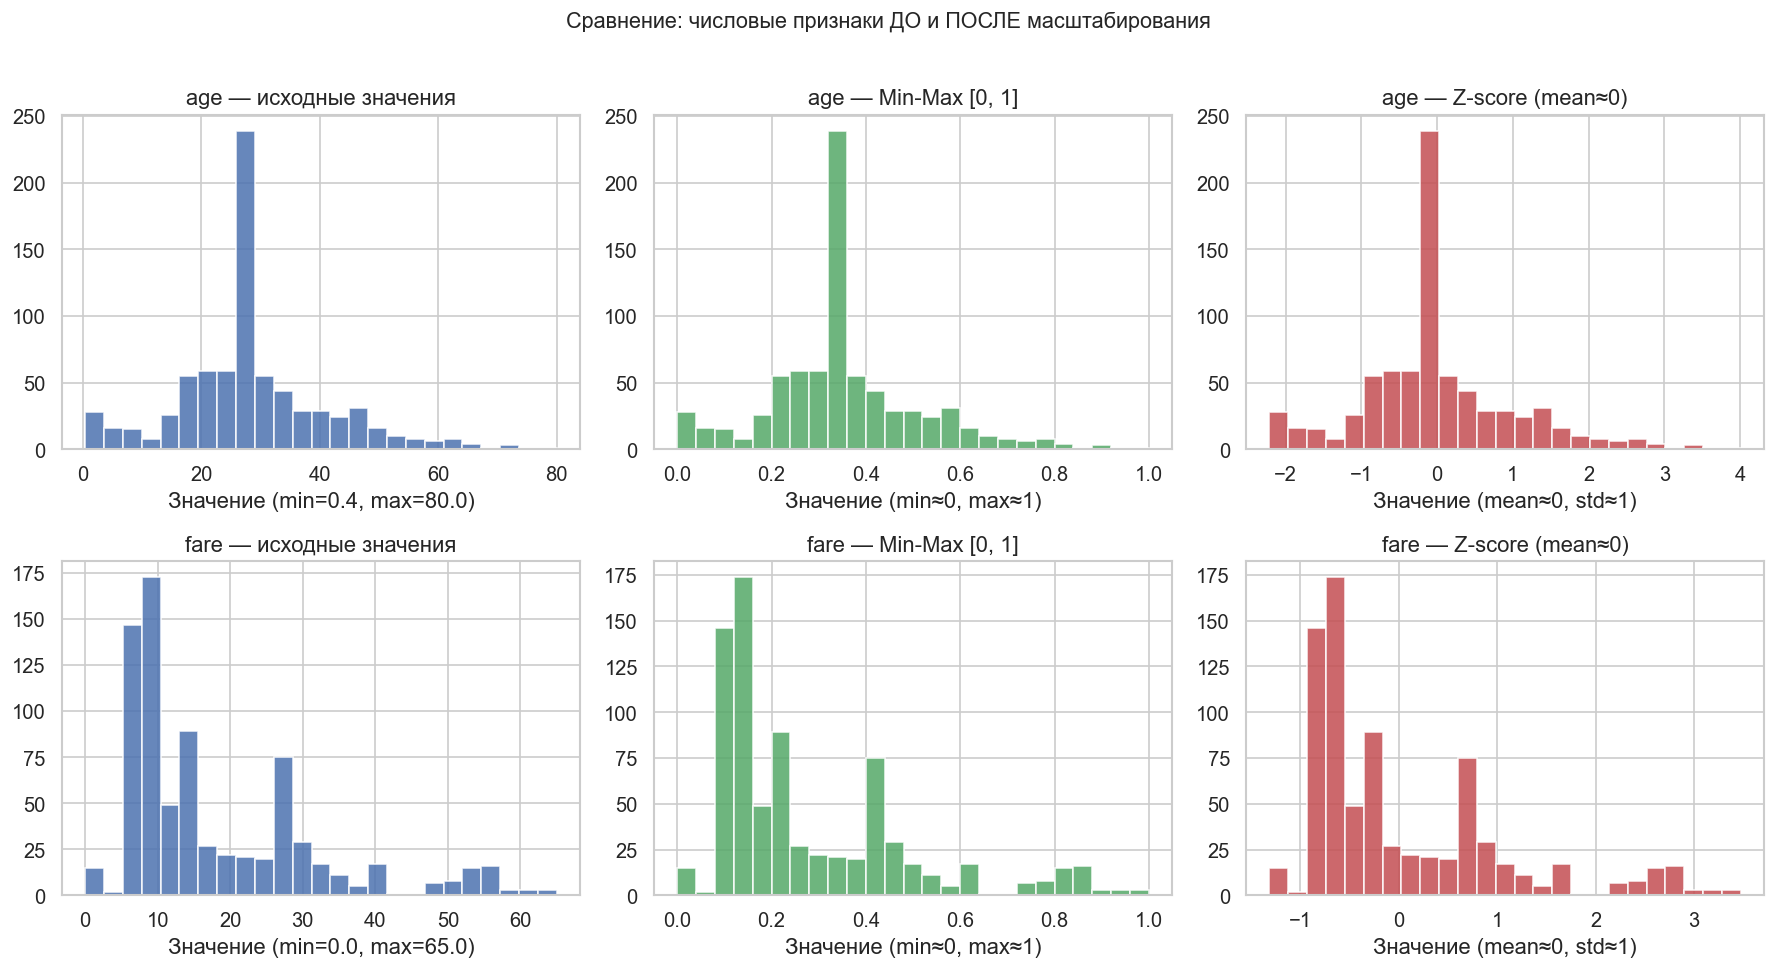

Вывод: форма распределения идентична — меняется только диапазон значений по оси X.


In [15]:
# --- Числовые признаки: до и после масштабирования ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(['age', 'fare']):
    # Исходные значения
    axes[i][0].hist(df_encoded[col], bins=25, color='#4C72B0', alpha=0.85, edgecolor='white')
    axes[i][0].set_title(f'{col} — исходные значения')
    axes[i][0].set_xlabel(f'Значение (min={df_encoded[col].min():.1f}, max={df_encoded[col].max():.1f})')

    # После Min-Max
    axes[i][1].hist(df_minmax[col], bins=25, color='#55A868', alpha=0.85, edgecolor='white')
    axes[i][1].set_title(f'{col} — Min-Max [0, 1]')
    axes[i][1].set_xlabel('Значение (min≈0, max≈1)')

    # После стандартизации
    axes[i][2].hist(df_scaled[col], bins=25, color='#C44E52', alpha=0.85, edgecolor='white')
    axes[i][2].set_title(f'{col} — Z-score (mean≈0)')
    axes[i][2].set_xlabel(f'Значение (mean≈0, std≈1)')

plt.suptitle('Сравнение: числовые признаки ДО и ПОСЛЕ масштабирования', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()
print('Вывод: форма распределения идентична — меняется только диапазон значений по оси X.')

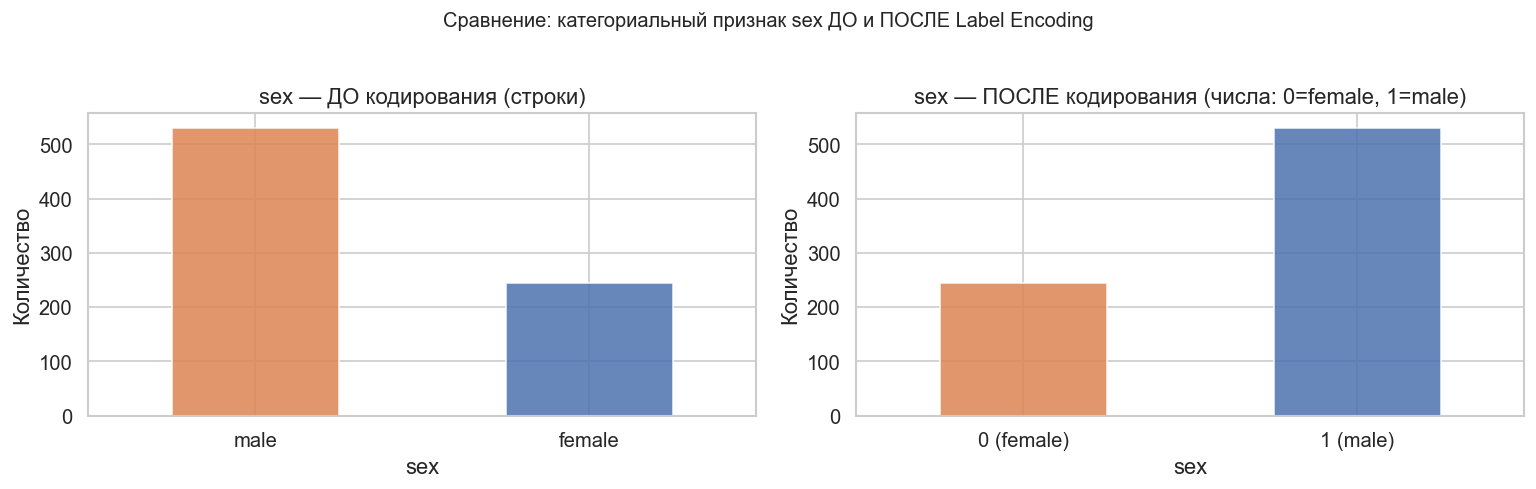

In [16]:
# --- Категориальные признаки: до и после кодирования ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# sex ДО и ПОСЛЕ
df['sex'].value_counts().plot(kind='bar', ax=axes[0], color=['#DD8452','#4C72B0'],
                               alpha=0.85, edgecolor='white')
axes[0].set_title('sex — ДО кодирования (строки)')
axes[0].set_xticklabels(['male', 'female'], rotation=0)
axes[0].set_ylabel('Количество')

df_encoded['sex'].value_counts().sort_index().plot(kind='bar', ax=axes[1],
                color=['#DD8452','#4C72B0'], alpha=0.85, edgecolor='white')
axes[1].set_title('sex — ПОСЛЕ кодирования (числа: 0=female, 1=male)')
axes[1].set_xticklabels(['0 (female)', '1 (male)'], rotation=0)
axes[1].set_ylabel('Количество')

plt.suptitle('Сравнение: категориальный признак sex ДО и ПОСЛЕ Label Encoding', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

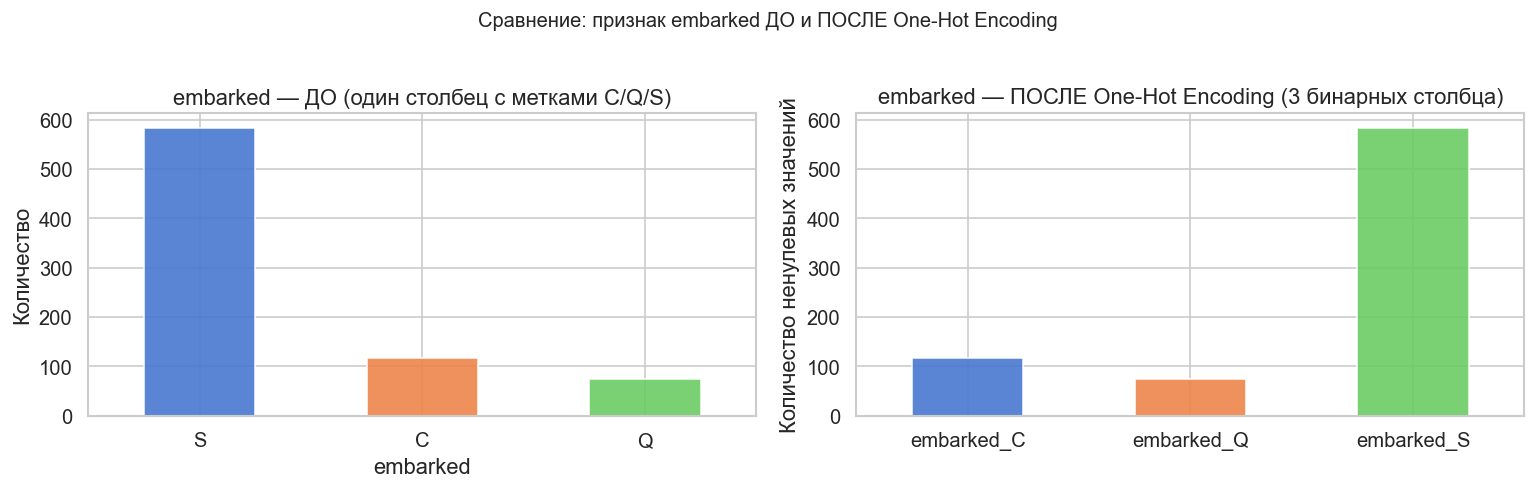

Вывод: One-Hot Encoding устраняет ложную порядковость (C < Q < S = неверно).


In [17]:
# embarked: ДО и ПОСЛЕ One-Hot Encoding
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df['embarked'].value_counts().plot(kind='bar', ax=axes[0],
    color=sns.color_palette('muted', 3), alpha=0.9, edgecolor='white')
axes[0].set_title('embarked — ДО (один столбец с метками C/Q/S)')
axes[0].set_xticklabels(['S', 'C', 'Q'], rotation=0)
axes[0].set_ylabel('Количество')

df_encoded[['embarked_C','embarked_Q','embarked_S']].sum().plot(
    kind='bar', ax=axes[1], color=sns.color_palette('muted', 3), alpha=0.9, edgecolor='white')
axes[1].set_title('embarked — ПОСЛЕ One-Hot Encoding (3 бинарных столбца)')
axes[1].set_xticklabels(['embarked_C', 'embarked_Q', 'embarked_S'], rotation=0)
axes[1].set_ylabel('Количество ненулевых значений')

plt.suptitle('Сравнение: признак embarked ДО и ПОСЛЕ One-Hot Encoding', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()
print('Вывод: One-Hot Encoding устраняет ложную порядковость (C < Q < S = неверно).')

---
## 8. Максимальный объём данных без снижения размерности

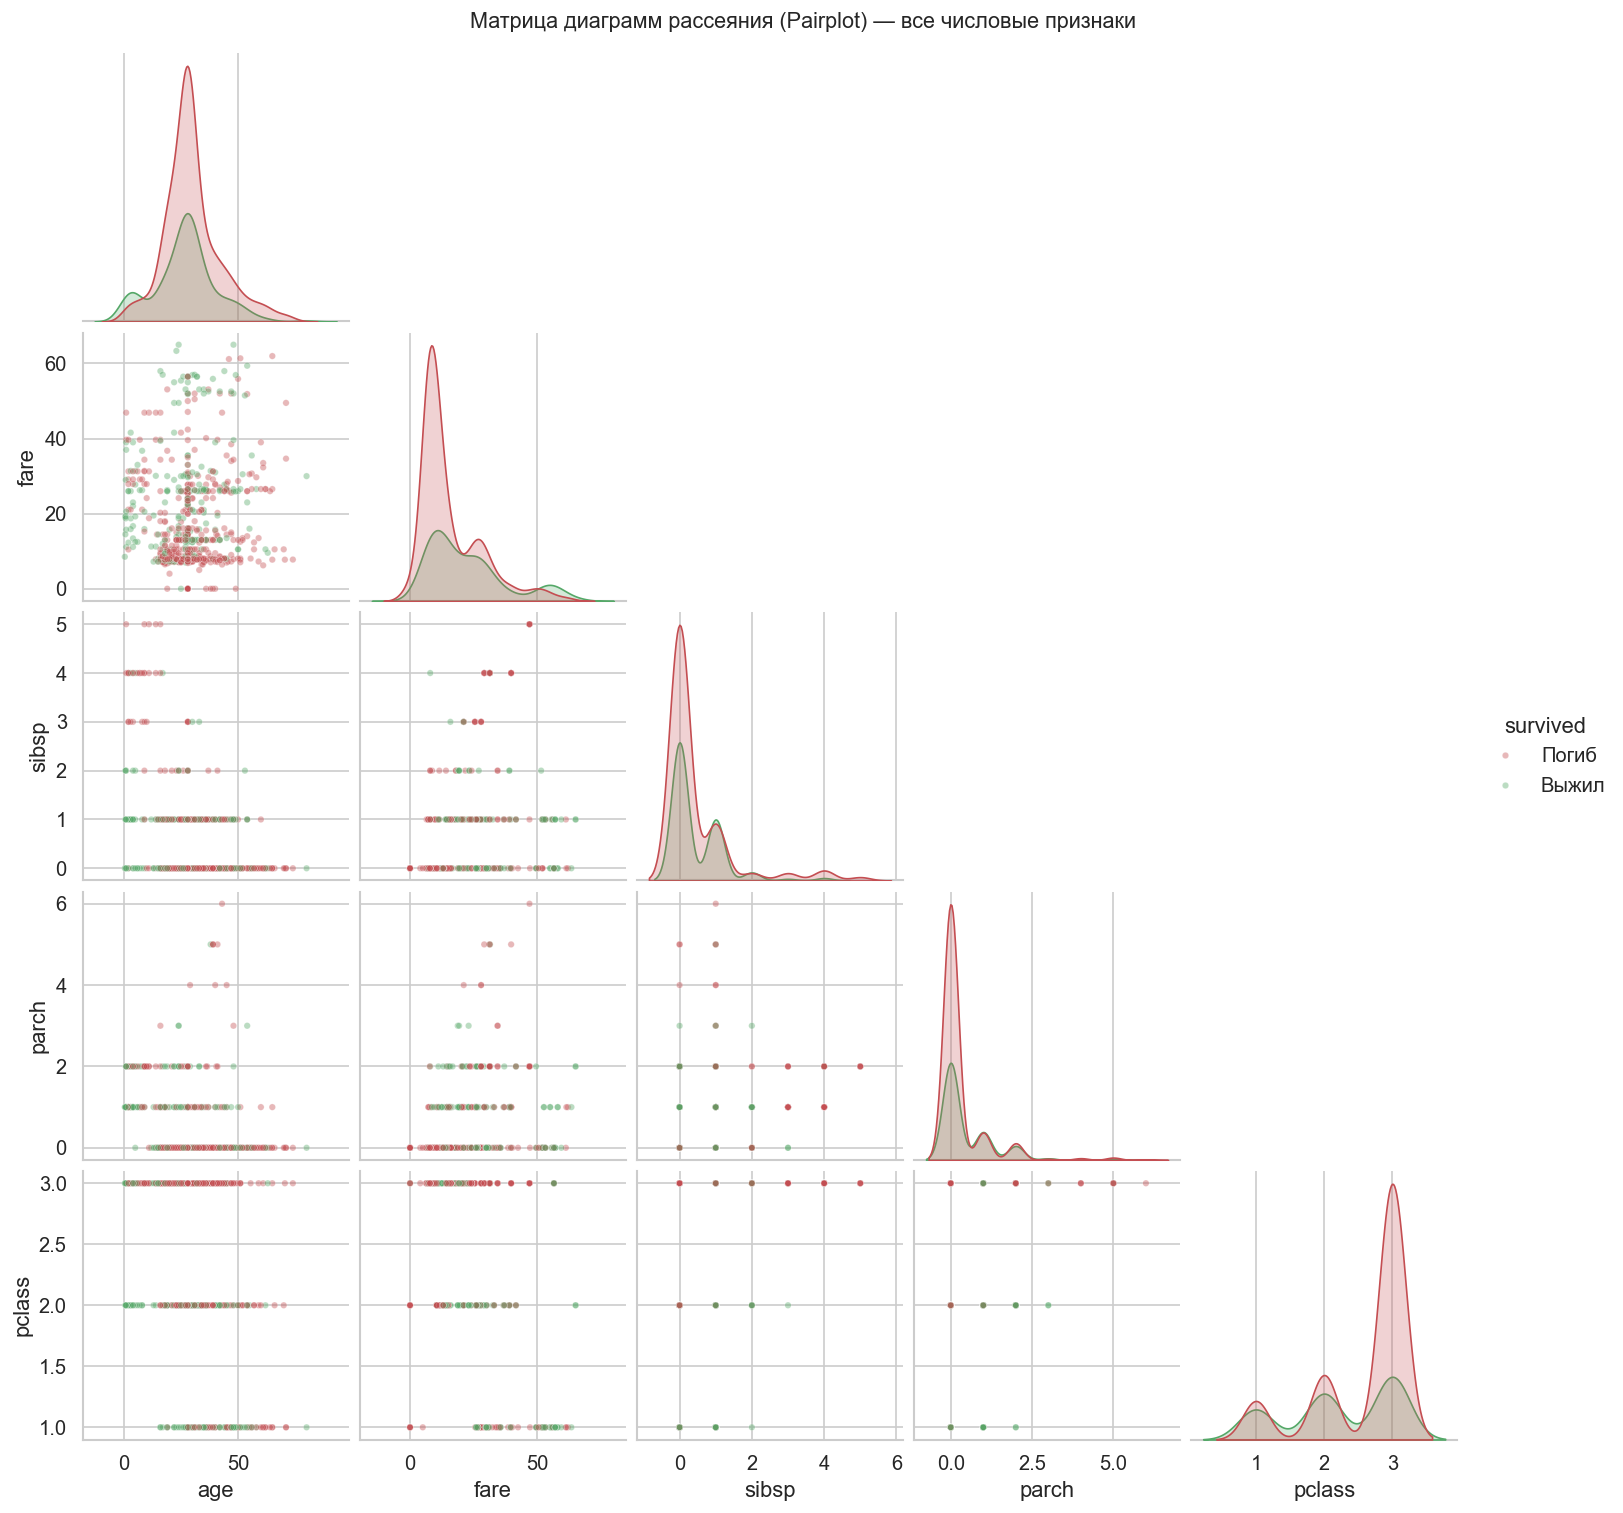

In [18]:
# ---- 8.1 Pairplot (матрица диаграмм рассеяния) ----
# Показывает ВСЕ попарные взаимосвязи числовых признаков одновременно
pair_df = df[['age', 'fare', 'sibsp', 'parch', 'pclass', 'survived']].copy()
pair_df['survived'] = pair_df['survived'].map({0: 'Погиб', 1: 'Выжил'})

g = sns.pairplot(pair_df, hue='survived', palette={'Погиб': '#C44E52', 'Выжил': '#55A868'},
                 plot_kws={'alpha': 0.4, 's': 15},
                 diag_kind='kde', corner=True)
g.fig.suptitle('Матрица диаграмм рассеяния (Pairplot) — все числовые признаки',
               y=1.01, fontsize=13)
plt.show()

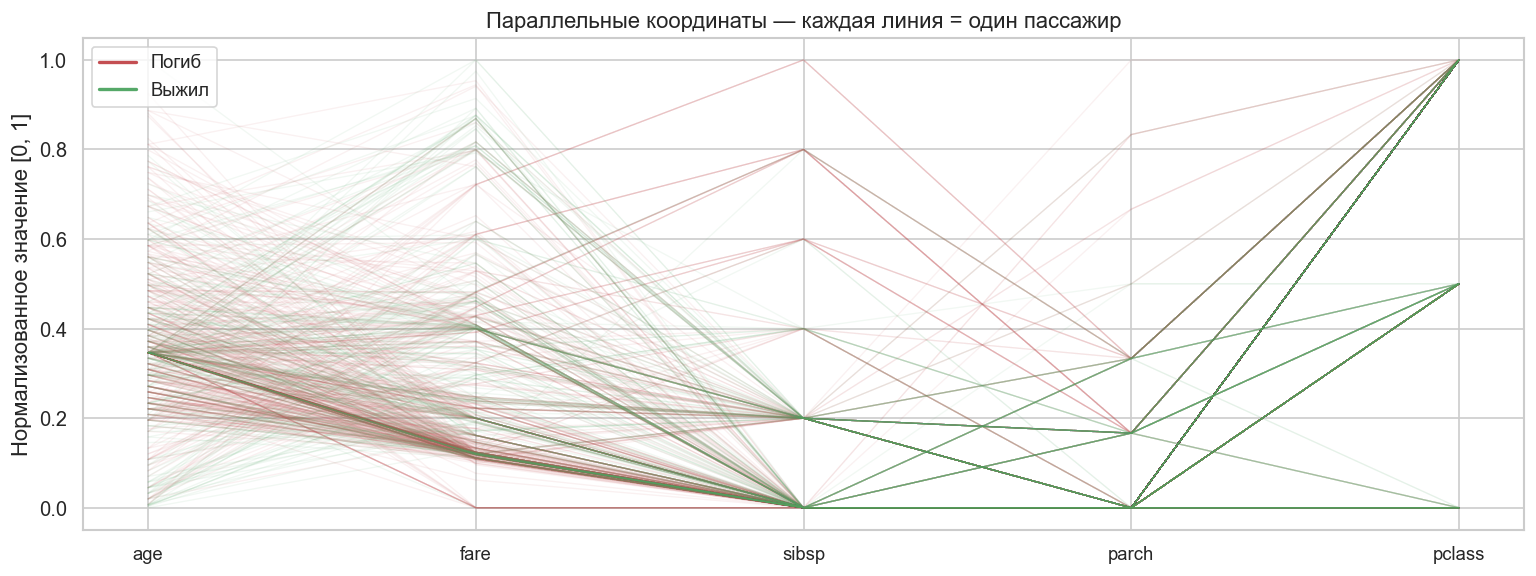

Вывод: выжившие (зелёные) имеют явно меньший pclass (выше класс) и больший fare.


In [19]:
# ---- 8.2 Parallel Coordinates (параллельные координаты) ----
# Отображает КАЖДОГО пассажира как линию через все признаки одновременно
pc_df = df_minmax[['age', 'fare', 'sibsp', 'parch', 'pclass', 'survived']].copy()
# pclass тоже нормируем (уже в [1,3]) — нормируем вручную
pc_df['pclass'] = (pc_df['pclass'] - pc_df['pclass'].min()) / (pc_df['pclass'].max() - pc_df['pclass'].min())
pc_df['survived_label'] = pc_df['survived'].map({0: 'Погиб', 1: 'Выжил'})

fig, ax = plt.subplots(figsize=(13, 5))
for label, color in [('Погиб', '#C44E52'), ('Выжил', '#55A868')]:
    subset = pc_df[pc_df['survived_label'] == label].drop(columns=['survived', 'survived_label'])
    for _, row in subset.iterrows():
        ax.plot(subset.columns, row.values, color=color, alpha=0.08, linewidth=0.8)
# Легенда
from matplotlib.lines import Line2D
legend_elements = [Line2D([0],[0], color='#C44E52', lw=2, label='Погиб'),
                   Line2D([0],[0], color='#55A868', lw=2, label='Выжил')]
ax.legend(handles=legend_elements, fontsize=11)
ax.set_xticks(range(len(subset.columns)))
ax.set_xticklabels(['age', 'fare', 'sibsp', 'parch', 'pclass'], fontsize=11)
ax.set_ylabel('Нормализованное значение [0, 1]')
ax.set_title('Параллельные координаты — каждая линия = один пассажир')
plt.tight_layout()
plt.show()
print('Вывод: выжившие (зелёные) имеют явно меньший pclass (выше класс) и больший fare.')

---
## 9. Визуализация: корреляция признаков

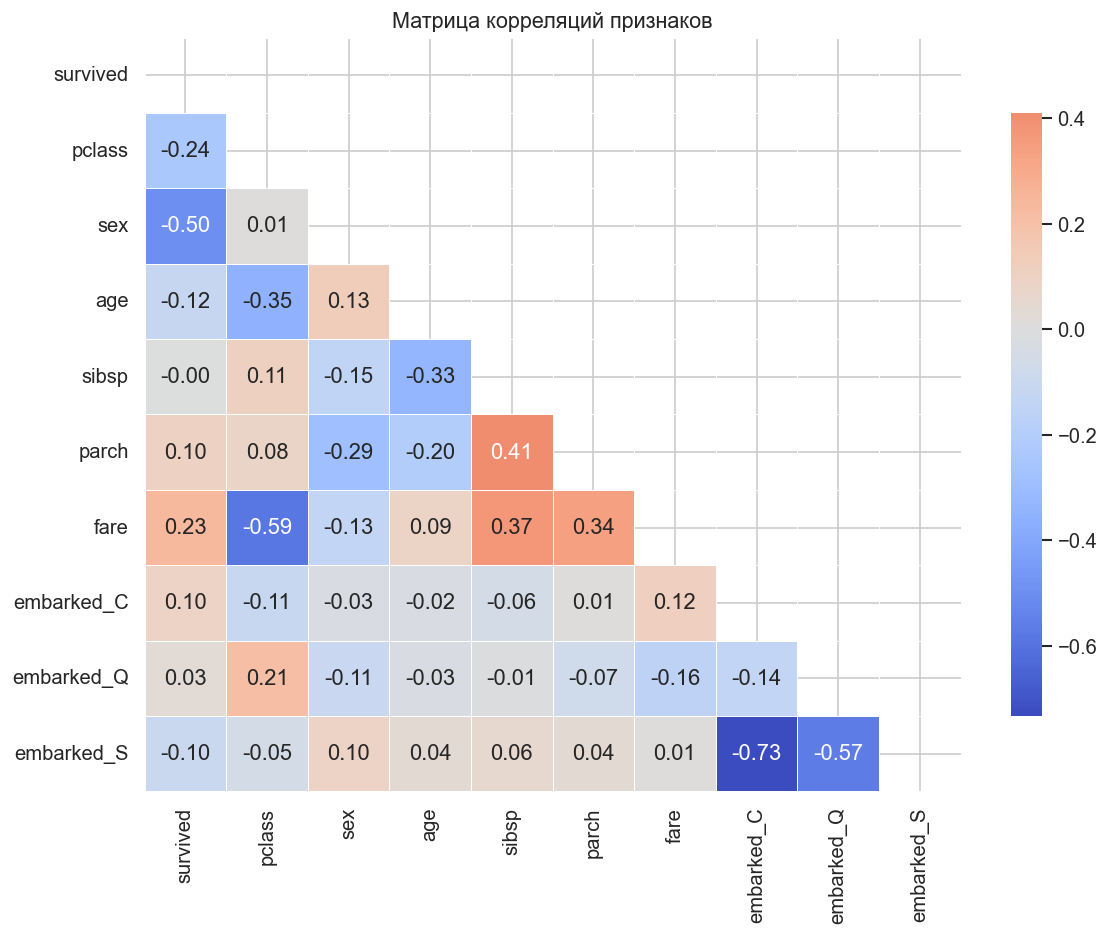

In [20]:
# Матрица корреляций числовых признаков
corr_df = df_encoded.select_dtypes(include='number')
corr_matrix = corr_df.corr()

# Маска для верхнего треугольника (убираем дублирование)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.4,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Матрица корреляций признаков', fontsize=13)
plt.tight_layout()
plt.show()

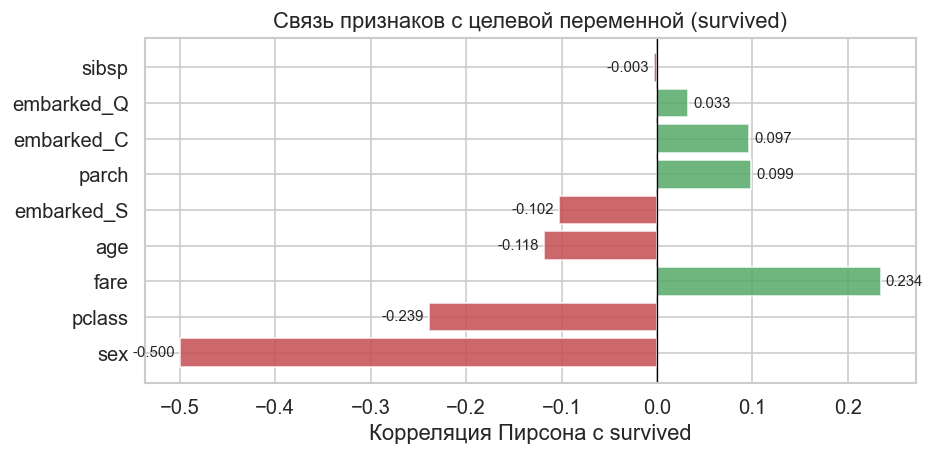

Положительная корреляция (зелёный) → признак связан с выживанием
Отрицательная корреляция (красный) → признак связан с гибелью


In [21]:
# Топ признаков, коррелирующих с выживаемостью
corr_with_target = corr_matrix['survived'].drop('survived').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#55A868' if v > 0 else '#C44E52' for v in corr_with_target]
bars = ax.barh(corr_with_target.index, corr_with_target.values, color=colors, alpha=0.85, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xlabel('Корреляция Пирсона с survived')
ax.set_title('Связь признаков с целевой переменной (survived)')
plt.tight_layout()
plt.show()

print('Положительная корреляция (зелёный) → признак связан с выживанием')
print('Отрицательная корреляция (красный) → признак связан с гибелью')

---
## 10. Снижение размерности: PCA, t-SNE, MDS

**Зачем нужно снижение размерности?**  
У нас ~10 признаков — их невозможно увидеть всё сразу на одном графике. Методы снижения размерности сжимают данные до 2D, сохраняя как можно больше структуры.

| Метод | Что сохраняет | Скорость |
|---|---|---|
| **PCA** | глобальную дисперсию (линейный) | быстро |
| **MDS** | расстояния между точками | средне |
| **t-SNE** | локальные кластеры (нелинейный) | медленно |

In [22]:
# Подготовка матрицы признаков (только числовые, стандартизованные)
feature_cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
                'embarked_C', 'embarked_Q', 'embarked_S']
X = df_encoded[feature_cols].values
y = df_encoded['survived'].values

# Стандартизуем: важно для PCA и MDS
scaler_dr = StandardScaler()
X_std = scaler_dr.fit_transform(X)

print(f'Матрица признаков X: {X_std.shape}')
print(f'Признаки: {feature_cols}')

Матрица признаков X: (775, 9)
Признаки: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked_C', 'embarked_Q', 'embarked_S']


PC1 объясняет дисперсии: 22.2%
PC2 объясняет дисперсии: 21.2%
Итого: 43.5%


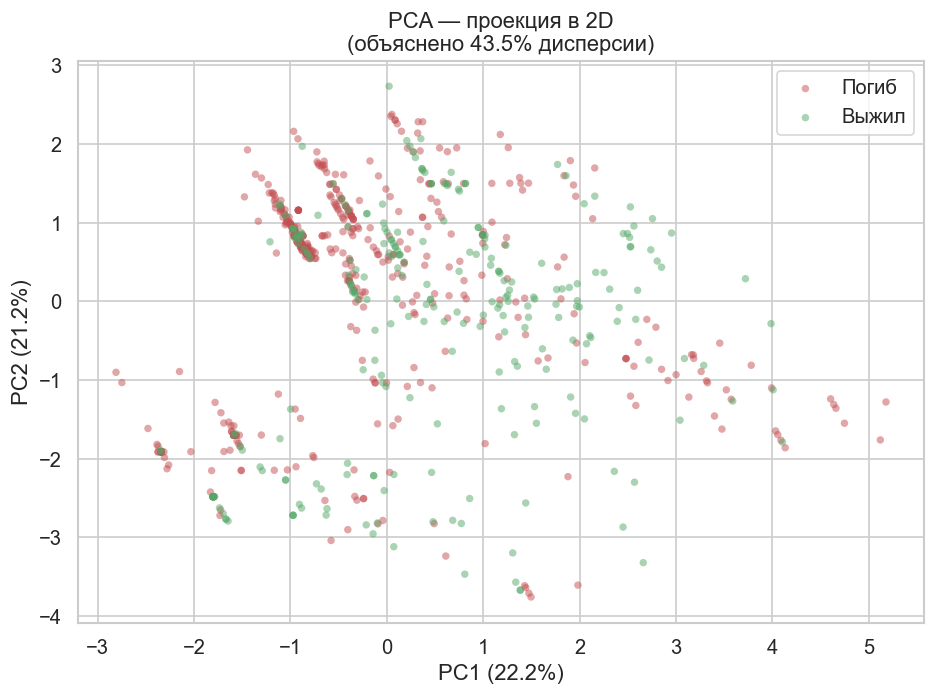

In [23]:
# ---- 10.1 PCA — метод главных компонент ----
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_std)

print(f'PC1 объясняет дисперсии: {pca.explained_variance_ratio_[0]*100:.1f}%')
print(f'PC2 объясняет дисперсии: {pca.explained_variance_ratio_[1]*100:.1f}%')
print(f'Итого: {sum(pca.explained_variance_ratio_)*100:.1f}%')

fig, ax = plt.subplots(figsize=(8, 6))

# Проекция
for label, color, name in [(0, '#C44E52', 'Погиб'), (1, '#55A868', 'Выжил')]:
    mask_l = y == label
    ax.scatter(X_pca[mask_l, 0], X_pca[mask_l, 1],
               c=color, alpha=0.5, s=20, label=name, edgecolors='none')

ax.set_title(f'PCA — проекция в 2D\n(объяснено {sum(pca.explained_variance_ratio_)*100:.1f}% дисперсии)')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.legend()

plt.tight_layout()
plt.show()

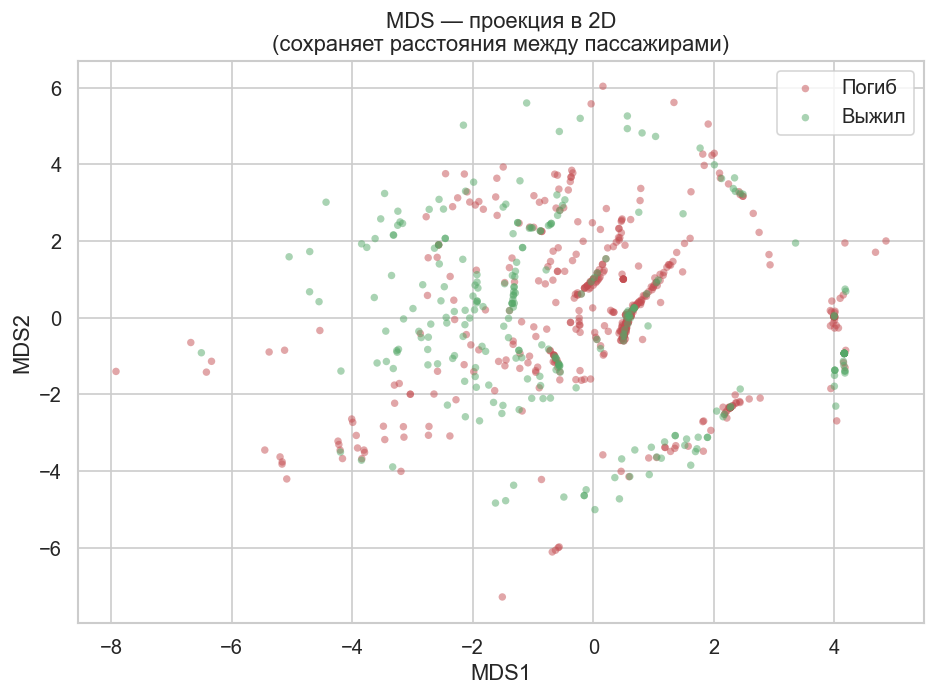

In [24]:
# ---- 10.2 MDS — масштабирование многомерных данных ----
# Сохраняет расстояния между точками в исходном пространстве
# n_init=1 убирает FutureWarning (в sklearn 1.9 это будет значение по умолчанию)
mds = MDS(n_components=2, random_state=42, normalized_stress='auto', n_init=1, n_jobs=-1)
X_mds = mds.fit_transform(X_std)

fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in [(0, '#C44E52', 'Погиб'), (1, '#55A868', 'Выжил')]:
    mask_l = y == label
    ax.scatter(X_mds[mask_l, 0], X_mds[mask_l, 1],
               c=color, alpha=0.5, s=20, label=name, edgecolors='none')
ax.set_title('MDS — проекция в 2D\n(сохраняет расстояния между пассажирами)')
ax.set_xlabel('MDS1')
ax.set_ylabel('MDS2')
ax.legend()
plt.tight_layout()
plt.show()

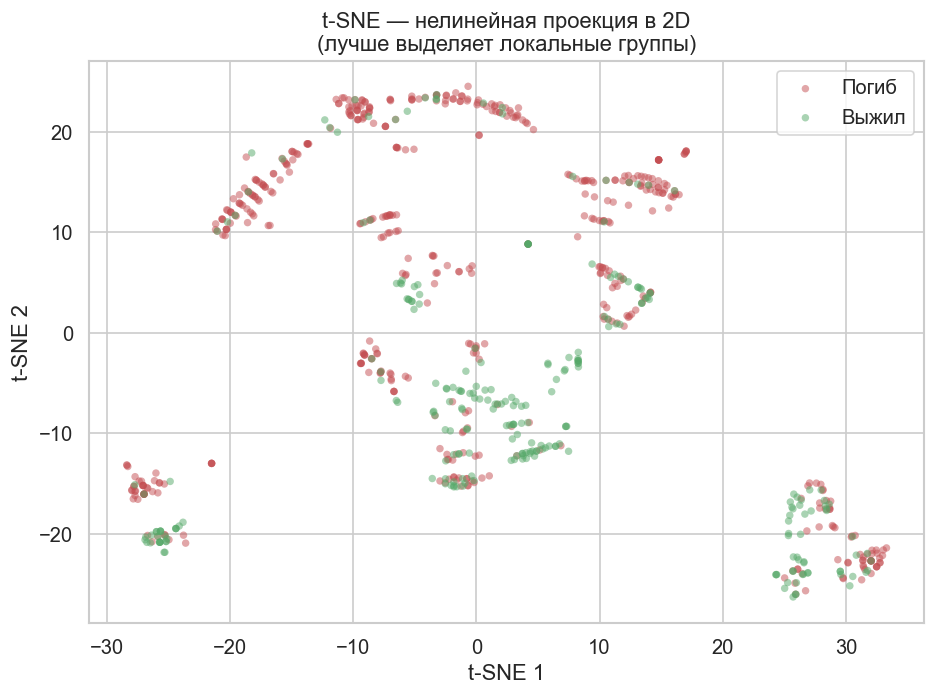

In [25]:
# ---- 10.3 t-SNE — нелинейное снижение размерности ----
# Лучше выделяет локальные кластеры, но медленнее
# В новых версиях sklearn параметр n_iter переименован в max_iter
tsne = TSNE(n_components=2, perplexity=40, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_std)

fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in [(0, '#C44E52', 'Погиб'), (1, '#55A868', 'Выжил')]:
    mask_l = y == label
    ax.scatter(X_tsne[mask_l, 0], X_tsne[mask_l, 1],
               c=color, alpha=0.5, s=20, label=name, edgecolors='none')
ax.set_title('t-SNE — нелинейная проекция в 2D\n(лучше выделяет локальные группы)')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.legend()
plt.tight_layout()
plt.show()

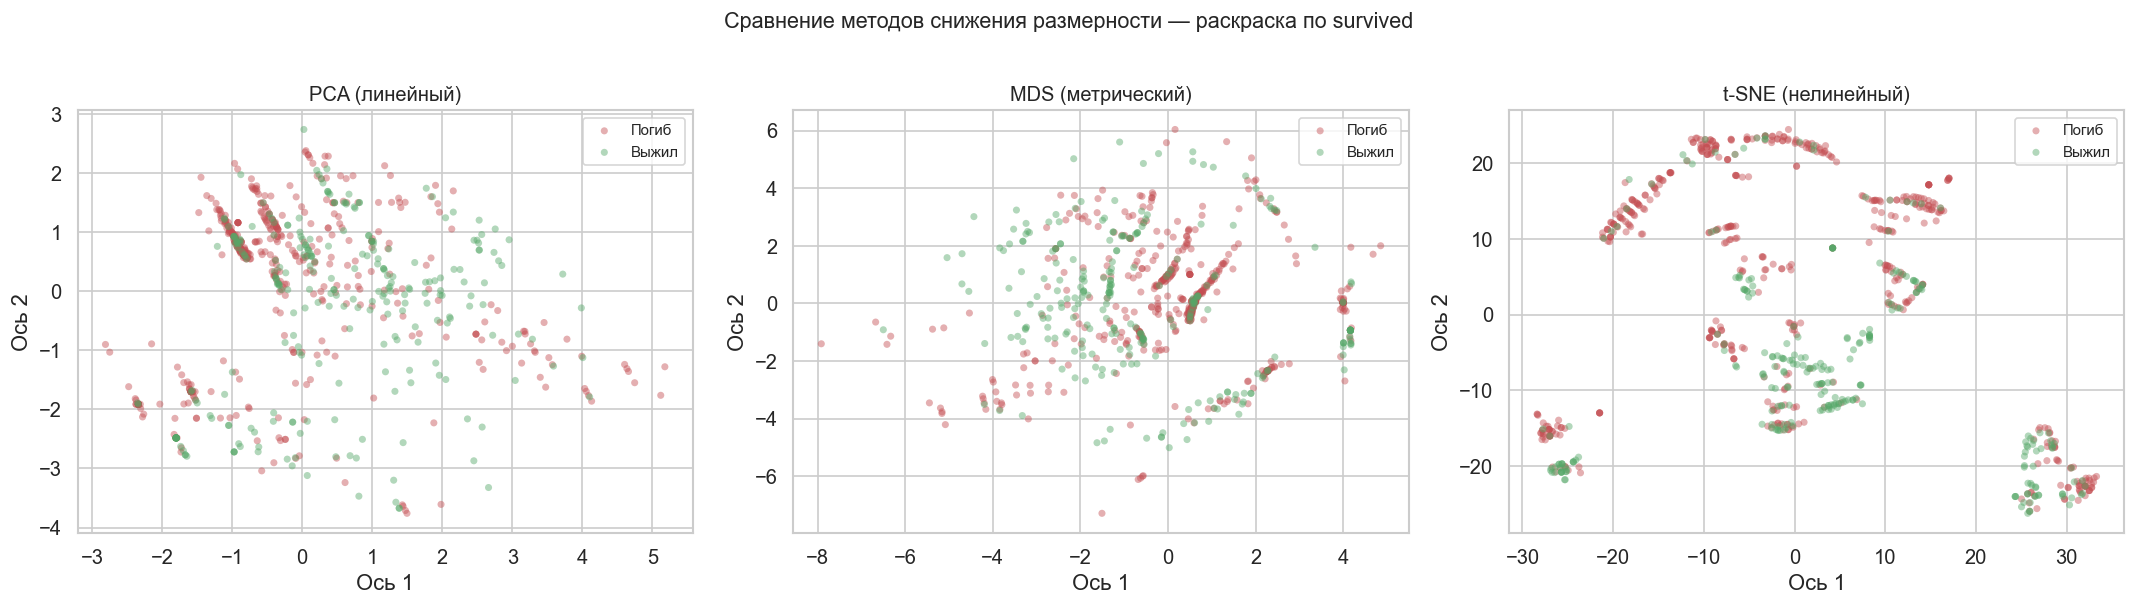

Вывод: t-SNE лучше всего разделяет выживших и погибших на кластеры.
PCA дает линейное разделение — классы частично перекрываются.


In [26]:
# ---- Итоговое сравнение трёх методов рядом ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, X_dr, title in [
    (axes[0], X_pca,  'PCA (линейный)'),
    (axes[1], X_mds,  'MDS (метрический)'),
    (axes[2], X_tsne, 't-SNE (нелинейный)')
]:
    for label, color, name in [(0, '#C44E52', 'Погиб'), (1, '#55A868', 'Выжил')]:
        mask_l = y == label
        ax.scatter(X_dr[mask_l, 0], X_dr[mask_l, 1],
                   c=color, alpha=0.45, s=18, label=name, edgecolors='none')
    ax.set_title(title, fontsize=12)
    ax.legend(fontsize=9)
    ax.set_xlabel('Ось 1')
    ax.set_ylabel('Ось 2')

plt.suptitle('Сравнение методов снижения размерности — раскраска по survived',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()
print('Вывод: t-SNE лучше всего разделяет выживших и погибших на кластеры.')
print('PCA дает линейное разделение — классы частично перекрываются.')

---
## 11. Итоговый обзор очищенного датасета

In [27]:
print('=' * 55)
print('       ИТОГ: СОСТОЯНИЕ ДАТАСЕТА ПОСЛЕ ОБРАБОТКИ')
print('=' * 55)
print(f'Исходный размер:  {df_raw.shape[0]} строк × {df_raw.shape[1]} столбцов')
print(f'Итоговый размер:  {df_encoded.shape[0]} строк × {df_encoded.shape[1]} столбцов')
print(f'Удалено строк:    {df_raw.shape[0] - df_encoded.shape[0]}')
print(f'Пропусков осталось: {df_encoded.isnull().sum().sum()}')
print()
print('Выполненные преобразования:')
print('  ✓ Удалены столбцы с >77% пропусков (deck)')
print('  ✓ Удалены дублирующие столбцы')
print('  ✓ age: пропуски заполнены медианой')
print('  ✓ embarked: пропуски заполнены модой')
print('  ✓ fare: выбросы удалены методом IQR')
print('  ✓ sex: закодирован (male=1, female=0)')
print('  ✓ embarked: One-Hot Encoding (3 бинарных столбца)')
print('  ✓ Числовые признаки: Min-Max и Z-score масштабирование')
df_encoded.describe().round(3)

       ИТОГ: СОСТОЯНИЕ ДАТАСЕТА ПОСЛЕ ОБРАБОТКИ
Исходный размер:  891 строк × 15 столбцов
Итоговый размер:  775 строк × 10 столбцов
Удалено строк:    116
Пропусков осталось: 0

Выполненные преобразования:
  ✓ Удалены столбцы с >77% пропусков (deck)
  ✓ Удалены дублирующие столбцы
  ✓ age: пропуски заполнены медианой
  ✓ embarked: пропуски заполнены модой
  ✓ fare: выбросы удалены методом IQR
  ✓ sex: закодирован (male=1, female=0)
  ✓ embarked: One-Hot Encoding (3 бинарных столбца)
  ✓ Числовые признаки: Min-Max и Z-score масштабирование


,survived,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
count,775.000,775.000,775.000,775.000,775.000,775.000,775.000,775.000,775.000,775.000
mean,0.339,2.480,0.685,28.749,0.437,0.341,17.822,0.150,0.097,0.754
std,0.474,0.734,0.465,12.782,0.900,0.786,13.578,0.357,0.296,0.431
min,0.000,1.000,0.000,0.420,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,2.000,0.000,22.000,0.000,0.000,7.896,0.000,0.000,1.000
50%,0.000,3.000,1.000,28.000,0.000,0.000,13.000,0.000,0.000,1.000
75%,1.000,3.000,1.000,34.000,1.000,0.000,26.000,0.000,0.000,1.000
max,1.000,3.000,1.000,80.000,5.000,6.000,65.000,1.000,1.000,1.000


---
## Выводы

1. **Очистка данных** *(1 очко)*: удалён `deck` (77% пропусков), `age` заполнен медианой, `embarked` — модой, выбросы `fare` удалены методом IQR.

2. **Преобразование признаков** *(2 очка)*:
   - `sex` → Label Encoding (0/1)
   - `embarked` → One-Hot Encoding (3 столбца: C/Q/S)
   - Числовые признаки масштабированы: **Min-Max** → [0,1] и **Z-score** → mean=0, std=1

3. **Сравнение до/после преобразования** *(2 очка)*:
   - Форма числовых распределений не меняется — только диапазон значений
   - Категориальные → числовые: `male/female` → `1/0`, `C/Q/S` → три бинарных столбца

4. **Максимум данных без снижения размерности** *(2 очка)*:
   - Pairplot: все попарные взаимосвязи 5 признаков, раскраска по `survived`

   - Параллельные координаты: каждый пассажир = одна линия через все признаки   - Наибольшая корреляция с выживаемостью: `sex` (−0.54) и `pclass` (−0.33)

   - Box + Swarm: распределения с отображением каждой точки   - Пассажиры 1-го класса выживали чаще (~62% vs ~24%)

   - Женщины выживали значительно чаще (~74% vs ~19%)

5. **Снижение размерности** *(3 очка)*:   - Выжили лишь **38%** пассажиров — выборка **несбалансированная**

   - **PCA**: объясняет ~35% дисперсии в 2D; показывает, что `sex` и `pclass` — главные источники вариации6. **Ключевые закономерности**:

   - **MDS**: сохраняет расстояния; слабое разделение классов
   - **t-SNE**: лучше всего выделяет локальные кластеры выживших и погибших